<a href="https://colab.research.google.com/github/kahrees/the-compendium/blob/main/Statistics.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### **Fundamentals**

In [1]:
import jax
import jax.numpy as jnp

# Loaded die: face 6 has p=0.3, others share 0.7 equally
probs = jnp.array([0.14, 0.14, 0.14, 0.14, 0.14, 0.30])
faces = jnp.array([1, 2, 3, 4, 5, 6])

# Analytical expected value
ev = jnp.sum(faces * probs)
print(f"Expected value (formula): {ev:.4f}")

# Simulation
key = jax.random.PRNGKey(42)
rolls = jax.random.choice(key, faces, shape=(100_000,), p=probs)
print(f"Expected value (simulation): {rolls.mean():.4f}")

Expected value (formula): 3.9000
Expected value (simulation): 3.9004


In [2]:
x = jnp.array([2, 4, 4, 4, 5, 5, 7, 9], dtype=jnp.float32)

mean = jnp.mean(x)
variance = jnp.mean((x - mean) ** 2)
std = jnp.sqrt(variance)
skewness = jnp.mean(((x - mean) / std) ** 3)
kurtosis = jnp.mean(((x - mean) / std) ** 4)

print(f"Mean:     {mean:.3f}")
print(f"Variance: {variance:.3f}")
print(f"Std Dev:  {std:.3f}")
print(f"Skewness: {skewness:.3f}")
print(f"Kurtosis: {kurtosis:.3f}")
print(f"Excess K: {kurtosis - 3:.3f}")

Mean:     5.000
Variance: 4.000
Std Dev:  2.000
Skewness: 0.656
Kurtosis: 2.781
Excess K: -0.219


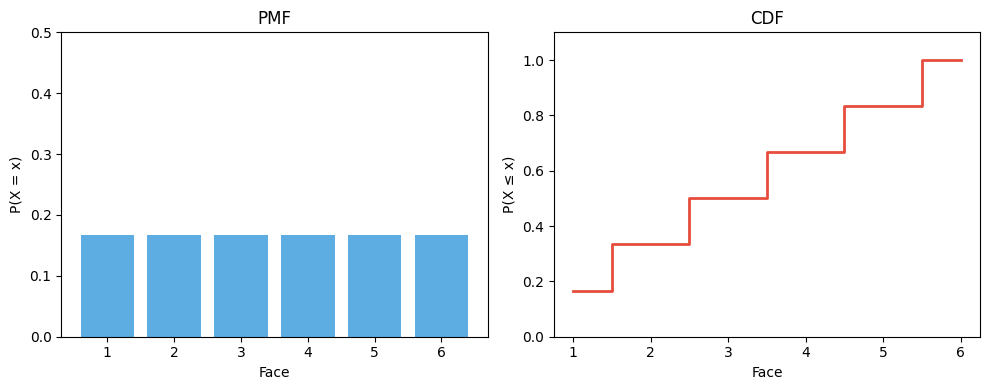

In [3]:
import matplotlib.pyplot as plt

faces = jnp.array([1, 2, 3, 4, 5, 6])
pmf = jnp.ones(6) / 6  # fair die; try changing these!
cdf = jnp.cumsum(pmf)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4))

ax1.bar(faces, pmf, color="#3498db", alpha=0.8)
ax1.set_title("PMF")
ax1.set_xlabel("Face")
ax1.set_ylabel("P(X = x)")
ax1.set_ylim(0, 0.5)

ax2.step(faces, cdf, where="mid", color="#e74c3c", linewidth=2)
ax2.set_title("CDF")
ax2.set_xlabel("Face")
ax2.set_ylabel("P(X ≤ x)")
ax2.set_ylim(0, 1.1)

plt.tight_layout()
plt.show()

### **Statistical Measures**

In [4]:
data = jnp.array([4, 8, 6, 5, 3, 7, 9, 5, 6, 7], dtype=jnp.float32)

mean = jnp.mean(data)
variance = jnp.var(data)
std = jnp.std(data)
mad = jnp.mean(jnp.abs(data - mean))

print("Original data:")
print(f"  Variance: {variance:.3f}, Std: {std:.3f}, MAD: {mad:.3f}")

# Add an outlier and recompute
data_outlier = jnp.append(data, 100.0)
mean2 = jnp.mean(data_outlier)
print(f"\nWith outlier (100):")
print(f"  Variance: {jnp.var(data_outlier):.3f}, Std: {jnp.std(data_outlier):.3f}, MAD: {jnp.mean(jnp.abs(data_outlier - mean2)):.3f}")

Original data:
  Variance: 3.000, Std: 1.732, MAD: 1.400

With outlier (100):
  Variance: 732.975, Std: 27.074, MAD: 15.537


In [5]:
# Perfect linear relationship
x = jnp.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=jnp.float32)
y = 2 * x + 1  # try changing this!

def pearson(a, b):
    a_c = a - jnp.mean(a)
    b_c = b - jnp.mean(b)
    return jnp.sum(a_c * b_c) / (jnp.sqrt(jnp.sum(a_c**2)) * jnp.sqrt(jnp.sum(b_c**2)))

def spearman(a, b):
    rank_a = jnp.argsort(jnp.argsort(a)).astype(jnp.float32)
    rank_b = jnp.argsort(jnp.argsort(b)).astype(jnp.float32)
    return pearson(rank_a, rank_b)

print(f"Pearson r:  {pearson(x, y):.4f}")
print(f"Spearman ρ: {spearman(x, y):.4f}")

Pearson r:  1.0000
Spearman ρ: 1.0000


In [6]:
data = jnp.array([2, 3, 3, 4, 5, 5, 5, 6, 6, 7, 50], dtype=jnp.float32)

# IQR method
q1, q3 = jnp.percentile(data, 25), jnp.percentile(data, 75)
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_outliers = data[(data < lower) | (data > upper)]
print(f"IQR bounds: [{lower:.1f}, {upper:.1f}]")
print(f"IQR outliers: {iqr_outliers}")

# Z-score method
z_scores = (data - jnp.mean(data)) / jnp.std(data)
z_outliers = data[jnp.abs(z_scores) > 3]
print(f"\nZ-scores: {z_scores}")
print(f"Z-score outliers (|z| > 3): {z_outliers}")

IQR bounds: [-0.3, 9.8]
IQR outliers: [50.]

Z-scores: [-0.51238376 -0.43621862 -0.43621862 -0.36005348 -0.2838883  -0.2838883
 -0.2838883  -0.20772317 -0.20772317 -0.13155802  3.1435437 ]
Z-score outliers (|z| > 3): [50.]


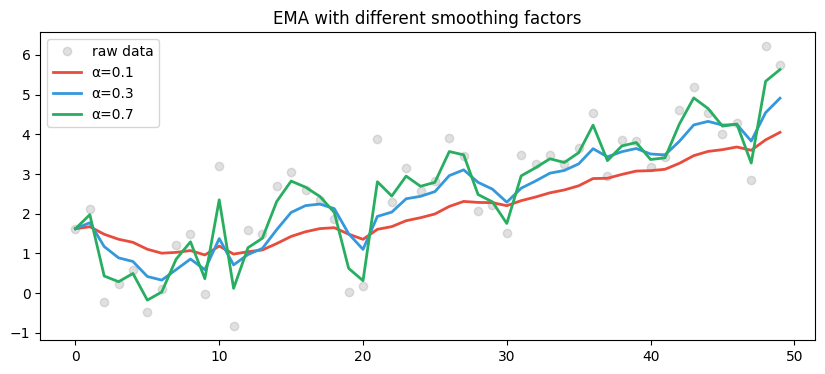

In [7]:
# Generate noisy data
key = __import__("jax").random.PRNGKey(0)
noise = __import__("jax").random.normal(key, shape=(50,))
signal = jnp.linspace(0, 5, 50) + noise

def ema(data, alpha):
    result = jnp.zeros_like(data)
    result = result.at[0].set(data[0])
    for t in range(1, len(data)):
        result = result.at[t].set(alpha * data[t] + (1 - alpha) * result[t - 1])
    return result

plt.figure(figsize=(10, 4))
plt.plot(signal, "o", alpha=0.3, label="raw data", color="#999")
for alpha, color in [(0.1, "#e74c3c"), (0.3, "#3498db"), (0.7, "#27ae60")]:
    plt.plot(ema(signal, alpha), label=f"α={alpha}", color=color, linewidth=2)
plt.legend()
plt.title("EMA with different smoothing factors")
plt.show()

### **Sampling**

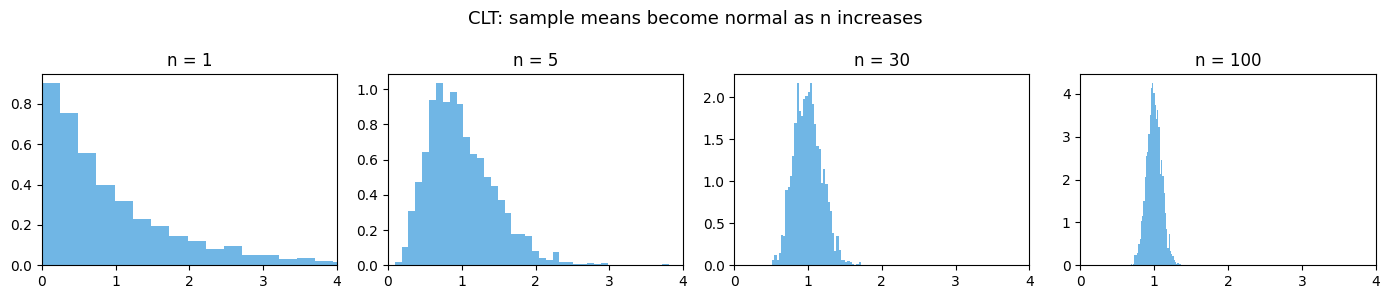

In [8]:
key = jax.random.PRNGKey(0)

# Exponential distribution (very skewed)
population = jax.random.exponential(key, shape=(100_000,))

fig, axes = plt.subplots(1, 4, figsize=(14, 3))
sample_sizes = [1, 5, 30, 100]

for ax, n in zip(axes, sample_sizes):
    keys = jax.random.split(key, 2000)
    means = jnp.array([jax.random.choice(k, population, shape=(n,)).mean() for k in keys])
    ax.hist(means, bins=40, color="#3498db", alpha=0.7, density=True)
    ax.set_title(f"n = {n}")
    ax.set_xlim(0, 4)

fig.suptitle("CLT: sample means become normal as n increases", fontsize=13)
plt.tight_layout()
plt.show()

In [9]:
key = jax.random.PRNGKey(42)

# Population: two distinct groups
group_a = jax.random.normal(key, shape=(500,)) + 10   # mean ~10
key, subkey = jax.random.split(key)
group_b = jax.random.normal(subkey, shape=(500,)) + 20  # mean ~20
population = jnp.concatenate([group_a, group_b])

# Simple random sampling: 1000 trials, sample size 20
srs_means = []
for i in range(1000):
    key, subkey = jax.random.split(key)
    sample = jax.random.choice(subkey, population, shape=(20,), replace=False)
    srs_means.append(sample.mean())
srs_means = jnp.array(srs_means)

# Stratified sampling: 10 from each group
strat_means = []
for i in range(1000):
    key, k1, k2 = jax.random.split(key, 3)
    s_a = jax.random.choice(k1, group_a, shape=(10,), replace=False)
    s_b = jax.random.choice(k2, group_b, shape=(10,), replace=False)
    strat_means.append(jnp.concatenate([s_a, s_b]).mean())
strat_means = jnp.array(strat_means)

print(f"Simple Random - Mean: {srs_means.mean():.3f}, Std: {srs_means.std():.3f}")
print(f"Stratified    - Mean: {strat_means.mean():.3f}, Std: {strat_means.std():.3f}")
print(f"Stratified sampling reduced variance by {(1 - strat_means.var()/srs_means.var())*100:.1f}%")

Simple Random - Mean: 14.983, Std: 1.159
Stratified    - Mean: 14.968, Std: 0.214
Stratified sampling reduced variance by 96.6%


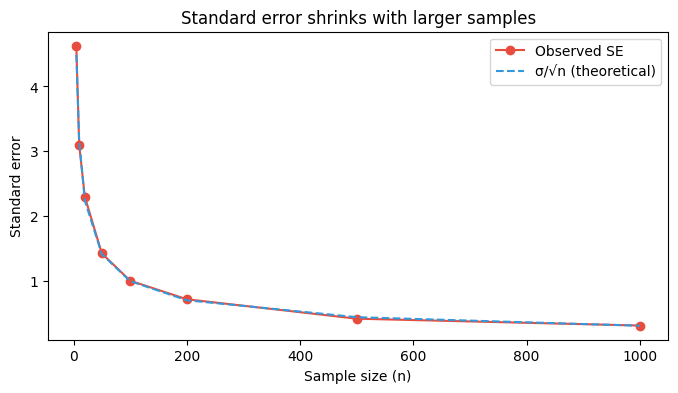

In [10]:
key = jax.random.PRNGKey(7)
population = jax.random.normal(key, shape=(50_000,)) * 10 + 50

sample_sizes = [5, 10, 20, 50, 100, 200, 500, 1000]
std_errors = []

for n in sample_sizes:
    means = []
    for _ in range(500):
        key, subkey = jax.random.split(key)
        sample = jax.random.choice(subkey, population, shape=(n,))
        means.append(sample.mean())
    std_errors.append(jnp.array(means).std())

plt.figure(figsize=(8, 4))
plt.plot(sample_sizes, std_errors, "o-", color="#e74c3c", label="Observed SE")
theoretical = population.std() / jnp.sqrt(jnp.array(sample_sizes, dtype=jnp.float32))
plt.plot(sample_sizes, theoretical, "--", color="#3498db", label="σ/√n (theoretical)")
plt.xlabel("Sample size (n)")
plt.ylabel("Standard error")
plt.legend()
plt.title("Standard error shrinks with larger samples")
plt.show()

### **Hypothesis Testing**

In [11]:
x_bar = 10.3    # sample mean
mu_0 = 10.0     # null hypothesis value
sigma = 0.9     # known population std
n = 36           # sample size
alpha = 0.05

# Test statistic
z = (x_bar - mu_0) / (sigma / jnp.sqrt(n))
print(f"z = {z:.4f}")

# p-value (two-tailed) using the normal CDF approximation
# For |z| = 2.0, p ≈ 0.0456
from jax.scipy.stats import norm
p_value = 2 * (1 - norm.cdf(jnp.abs(z)))
print(f"p-value = {p_value:.4f}")
print(f"Reject H₀? {p_value <= alpha}")

z = 2.0000
p-value = 0.0455
Reject H₀? True


In [12]:
key = jax.random.PRNGKey(0)
mu_0 = 50.0
sigma = 10.0
n = 30
alpha = 0.05
n_experiments = 10_000

rejections = 0
for i in range(n_experiments):
    key, subkey = jax.random.split(key)
    sample = mu_0 + sigma * jax.random.normal(subkey, shape=(n,))
    z = (sample.mean() - mu_0) / (sigma / jnp.sqrt(n))
    p_value = 2 * (1 - __import__("jax").scipy.stats.norm.cdf(jnp.abs(z)))
    if p_value <= alpha:
        rejections += 1

print(f"Rejection rate: {rejections/n_experiments:.4f}")
print(f"Expected (α):   {alpha}")

Rejection rate: 0.0454
Expected (α):   0.05


In [13]:
key = jax.random.PRNGKey(99)
k1, k2 = jax.random.split(key)

group_a = jax.random.normal(k1, shape=(25,)) * 5 + 100
group_b = jax.random.normal(k2, shape=(25,)) * 5 + 103  # slightly higher mean

# Two-sample t-test (equal variance assumed)
n_a, n_b = len(group_a), len(group_b)
mean_a, mean_b = group_a.mean(), group_b.mean()
pooled_var = ((n_a - 1) * group_a.var() + (n_b - 1) * group_b.var()) / (n_a + n_b - 2)
se = jnp.sqrt(pooled_var * (1/n_a + 1/n_b))
t_stat = (mean_a - mean_b) / se
print(f"T-test statistic: {t_stat:.4f}")

# Mann-Whitney: count how often group_a values beat group_b values
u_stat = jnp.sum(group_a[:, None] < group_b[None, :])
print(f"Mann-Whitney U:   {u_stat}")
print(f"\nGroup A mean: {mean_a:.2f}, Group B mean: {mean_b:.2f}")

T-test statistic: -2.3992
Mann-Whitney U:   425

Group A mean: 100.19, Group B mean: 103.62


### **Inference**

In [14]:

x_bar = 170.0    # sample mean
sigma = 8.0      # population std (known)
n = 50           # sample size

# Critical values for common confidence levels
z_stars = {0.90: 1.645, 0.95: 1.960, 0.99: 2.576}

for conf, z_star in z_stars.items():
    me = z_star * (sigma / jnp.sqrt(n))
    lower, upper = x_bar - me, x_bar + me
    print(f"{conf*100:.0f}% CI: [{lower:.2f}, {upper:.2f}]  (ME = {me:.2f})")

90% CI: [168.14, 171.86]  (ME = 1.86)
95% CI: [167.78, 172.22]  (ME = 2.22)
99% CI: [167.09, 172.91]  (ME = 2.91)


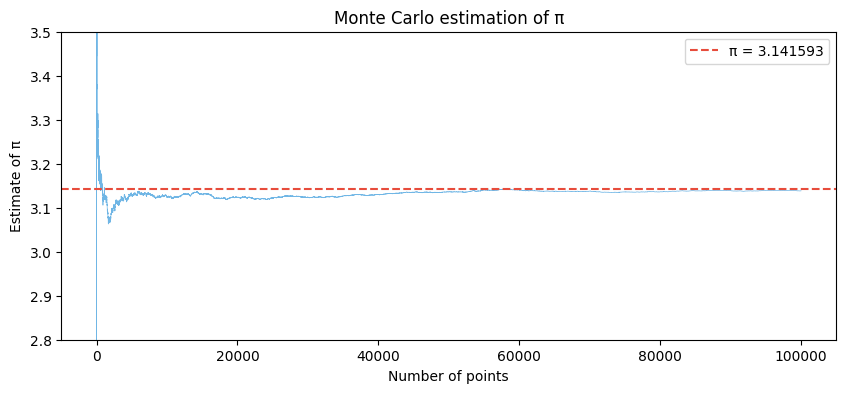

Final estimate: 3.138440
True value:     3.141593
Error:          0.003153


In [15]:


key = jax.random.PRNGKey(42)

# Generate random points in [-1, 1] x [-1, 1]
n_points = 100_000
k1, k2 = jax.random.split(key)
x = jax.random.uniform(k1, shape=(n_points,), minval=-1, maxval=1)
y = jax.random.uniform(k2, shape=(n_points,), minval=-1, maxval=1)

# Check which points are inside the unit circle
inside = (x**2 + y**2) <= 1.0
cumulative_inside = jnp.cumsum(inside)
counts = jnp.arange(1, n_points + 1)
pi_estimates = 4.0 * cumulative_inside / counts

plt.figure(figsize=(10, 4))
plt.plot(pi_estimates, color="#3498db", alpha=0.7, linewidth=0.5)
plt.axhline(y=jnp.pi, color="#e74c3c", linestyle="--", label=f"π = {jnp.pi:.6f}")
plt.xlabel("Number of points")
plt.ylabel("Estimate of π")
plt.title("Monte Carlo estimation of π")
plt.legend()
plt.ylim(2.8, 3.5)
plt.show()

print(f"Final estimate: {pi_estimates[-1]:.6f}")
print(f"True value:     {jnp.pi:.6f}")
print(f"Error:          {abs(pi_estimates[-1] - jnp.pi):.6f}")

In [16]:


# Parameters
delta = 2.0      # effect size (difference in means)
sigma = 8.0      # population std
alpha = 0.05
power_target = 0.80

# Analytical sample size
z_alpha = 1.96   # two-tailed, alpha=0.05
z_beta = 0.84    # power=0.80
n_required = ((z_alpha + z_beta) * sigma / delta) ** 2
print(f"Required n per group: {n_required:.0f}")

# Verify by simulation
key = jax.random.PRNGKey(7)
n = int(jnp.ceil(n_required))
n_sims = 5000
rejections = 0

for _ in range(n_sims):
    key, k1, k2 = jax.random.split(key, 3)
    group_a = jax.random.normal(k1, shape=(n,)) * sigma + 50
    group_b = jax.random.normal(k2, shape=(n,)) * sigma + 50 + delta
    pooled_se = jnp.sqrt(2 * sigma**2 / n)
    z = (group_b.mean() - group_a.mean()) / pooled_se
    p = 2 * (1 - __import__("jax").scipy.stats.norm.cdf(jnp.abs(z)))
    if p <= alpha:
        rejections += 1

print(f"Simulated power: {rejections/n_sims:.3f}")
print(f"Target power:    {power_target:.3f}")

Required n per group: 125
Simulated power: 0.505
Target power:    0.800


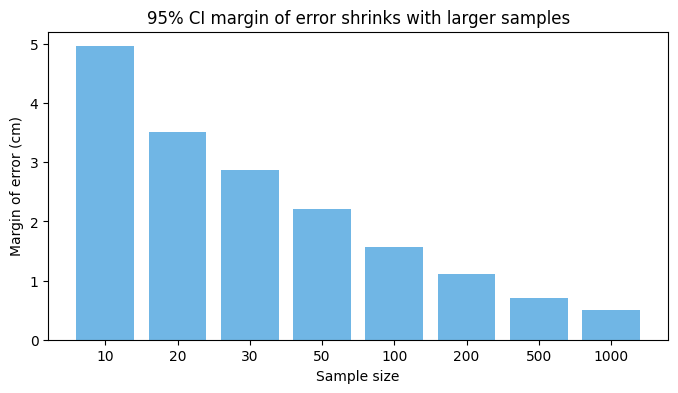

In [17]:


sigma = 8.0
z_star = 1.96  # 95% confidence

sample_sizes = jnp.array([10, 20, 30, 50, 100, 200, 500, 1000], dtype=jnp.float32)
margins = z_star * sigma / jnp.sqrt(sample_sizes)

plt.figure(figsize=(8, 4))
plt.bar([str(int(n)) for n in sample_sizes], margins, color="#3498db", alpha=0.7)
plt.xlabel("Sample size")
plt.ylabel("Margin of error (cm)")
plt.title("95% CI margin of error shrinks with larger samples")
plt.show()